<a href="https://colab.research.google.com/github/mashadiyevasabina/AB-Test.Project/blob/main/Business_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Yandex.Afisha Mərkəzi

Bu layihədə "Yandex.Afisha" platformasının analitik verillənləri əsasında marketinq xərclərinin optimallaşdırılması məqsədilə aşağıdakı əsas istiqamətlər araşdırılacaq:

Məhsul Metrikaları: İstifadəçilərin platformadan istifadə tezliyi (DAU, WAU, MAU), sessiya müddətləri (ASL) və platformaya qayıtma dərəcəsi (Retention Rate).

Satış və Konversiya: İlk ziyarətdən alışa qədər keçən vaxt, müştəri başına düşən orta sifariş sayısı və orta çek məbləği (AOV).

Müştəri Dəyəri və Rentabellik: Müştərinin platformaya gətirdiyi ömürlük gəlir (LTV), cəlb olunma xərcləri (CAC) və reklam kanallarının gəlirliliyi (ROMI).

Məqsəd effektiv işləməyən reklam kanallarını müəyyən edərək büdcəni daha qazanclı mənbələrə yönəltməkdir.

İstifadə Ediləcək Datasetlər və Sütunlar

Bu layihədə analiz üçün 3 ana cədvəldən (visits, orders, costs) istifadə edəcəyik:

1. visits (İstifadəçi Ziyarətləri)
İstifadəçilərin platformaya giriş və çıxış məlumatlarını saxlayır.

User Id — İstifadəçinin unikal identifikatoru.

Device — İstifadəçinin daxil olduğu cihaz növdü (desktop/touch).

Start Ts — Sessiyanın başlama tarixi və vaxtı.

End Ts — Sessiyanın bitmə tarixi və vaxtı.

Source Id — İstifadəçinin gəldiyi reklam kanalının ID-si.

2. orders (Sifarişlər)
İstifadəçilərin etdiyi alış-veriş məlumatlarını saxlayır.

User Id — Sifarişi edən istifadəçinin unikal ID-si.

Buy Ts — Sifarişin həyata keçirildiyi tarix və vaxt.

Revenue — Sifarişdən əldə olunan gəlir (məbləğ).

3. costs (Marketinq Xərcləri)
Reklam kanallarına çəkilən xərcləri saxlayır.

Source Id — Reklam kanalının unikal ID-si.

Dt — Xərcin çəkildiyi tarix.

Costs — Həmin gün həmin kanala xərclənən məbləğ.

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [66]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

In [67]:
visits = pd.read_csv('/content/drive/MyDrive/Business Analytics 3/visits_log_us.csv')
orders = pd.read_csv('/content/drive/MyDrive/Business Analytics 3/orders_log_us.csv')
costs = pd.read_csv('/content/drive/MyDrive/Business Analytics 3/costs_us.csv')

In [68]:
visits.head()

,Device,End Ts,Source Id,Start Ts,Uid
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168


In [69]:
visits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   Device     359400 non-null  object
 1   End Ts     359400 non-null  object
 2   Source Id  359400 non-null  int64 
 3   Start Ts   359400 non-null  object
 4   Uid        359400 non-null  uint64
dtypes: int64(1), object(3), uint64(1)
memory usage: 13.7+ MB


In [70]:
#  Tiplərin optimallaşdırılması və düzəldilməsi
visits['Start Ts'] = pd.to_datetime(visits['Start Ts'])
visits['End Ts'] = pd.to_datetime(visits['End Ts'])


In [71]:
# Sütun adlarını rahat istifadə üçün kiçik hərflərə çevirək
visits.columns = [c.lower().replace(' ', '_') for c in visits.columns]

In [72]:
orders.head()

,Buy Ts,Revenue,Uid
0,2017-06-01 00:10:00,17.00,10329302124590727494
1,2017-06-01 00:25:00,0.55,11627257723692907447
2,2017-06-01 00:27:00,0.37,17903680561304213844
3,2017-06-01 00:29:00,0.55,16109239769442553005
4,2017-06-01 07:58:00,0.37,14200605875248379450


In [73]:
orders.columns = [c.lower().replace(' ', '_') for c in orders.columns]

In [74]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   buy_ts   50415 non-null  object 
 1   revenue  50415 non-null  float64
 2   uid      50415 non-null  uint64 
dtypes: float64(1), object(1), uint64(1)
memory usage: 1.2+ MB


In [75]:
orders['buy_ts'] = pd.to_datetime(orders['buy_ts'])

In [76]:
costs.head()

,source_id,dt,costs
0,1,2017-06-01,75.20
1,1,2017-06-02,62.25
2,1,2017-06-03,36.53
3,1,2017-06-04,55.00
4,1,2017-06-05,57.08


In [77]:
costs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   source_id  2542 non-null   int64  
 1   dt         2542 non-null   object 
 2   costs      2542 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 59.7+ KB


In [78]:
costs['dt'] = pd.to_datetime(costs['dt'])

#Adım 2. Hesabatların hazırlanması və metrikaların hesablanması
##1. Məhsul (Product):

##Gündəlik, həftəlik və aylıq neçə nəfər məhsuldan istifadə edir? (DAU, WAU, MAU)

In [79]:
# Tarix sütunlarının ayrılması
visits['session_year'] = visits['start_ts'].dt.year
visits['session_month'] = visits['start_ts'].dt.to_period('M')
visits['session_week'] = visits['start_ts'].dt.to_period('W')
visits['session_date'] = visits['start_ts'].dt.date
visits

,device,end_ts,source_id,start_ts,uid,session_year,session_month,session_week,session_date
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062,2017,2017-12,2017-12-18/2017-12-24,2017-12-20
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740,2018,2018-02,2018-02-19/2018-02-25,2018-02-19
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527,2017,2017-07,2017-06-26/2017-07-02,2017-07-01
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214,2018,2018-05,2018-05-14/2018-05-20,2018-05-20
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168,2017,2017-12,2017-12-25/2017-12-31,2017-12-27
...,...,...,...,...,...,...,...,...,...
359395,desktop,2017-07-29 19:07:19,2,2017-07-29 19:07:00,18363291481961487539,2017,2017-07,2017-07-24/2017-07-30,2017-07-29
359396,touch,2018-01-25 17:38:19,1,2018-01-25 17:38:00,18370831553019119586,2018,2018-01,2018-01-22/2018-01-28,2018-01-25
359397,desktop,2018-03-03 10:12:19,4,2018-03-03 10:12:00,18387297585500748294,2018,2018-03,2018-02-26/2018-03-04,2018-03-03
359398,desktop,2017-11-02 10:12:19,5,2017-11-02 10:12:00,18388616944624776485,2017,2017-11,2017-10-30/2017-11-05,2017-11-02


In [80]:
# Metrikaların hesablanması
dau = visits.groupby('session_date').agg({'uid': 'nunique'})['uid'].mean()
wau = visits.groupby('session_week').agg({'uid': 'nunique'})['uid'].mean()
mau = visits.groupby('session_month').agg({'uid': 'nunique'})['uid'].mean()

print(f"Orta Gündəlik Aktiv İstifadəçi Sayı (DAU): {int(dau)}")
print(f"Orta Həftəlik Aktiv İstifadəçi Sayı (WAU): {int(wau)}")
print(f"Orta Aylıq Aktiv İstifadəçi Sayı (MAU): {int(mau)}")

Orta Gündəlik Aktiv İstifadəçi Sayı (DAU): 907
Orta Həftəlik Aktiv İstifadəçi Sayı (WAU): 5716
Orta Aylıq Aktiv İstifadəçi Sayı (MAU): 23228


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 601 (\N{LATIN SMALL LETTER SCHWA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


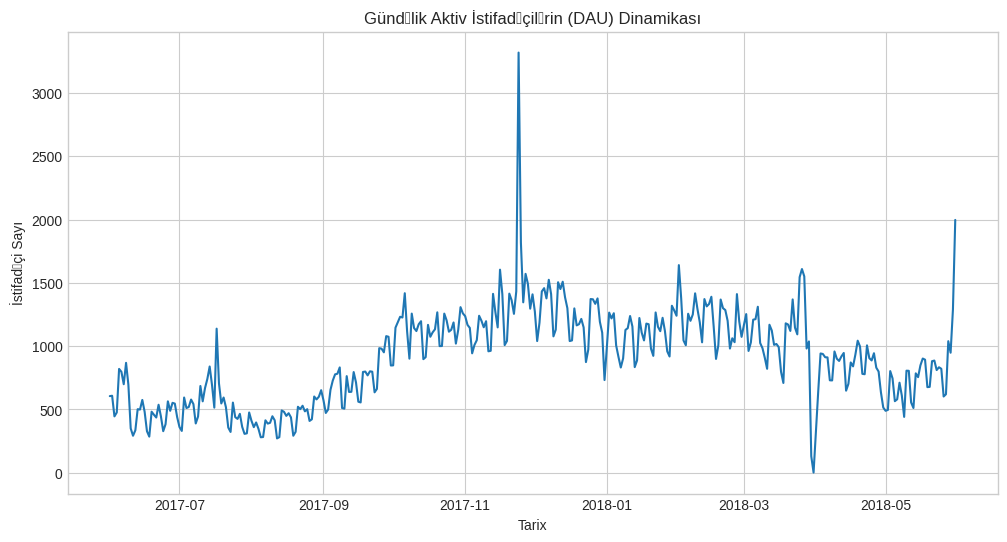

In [81]:
# DAU dinamikasının qrafiki
visits.groupby('session_date').agg({'uid': 'nunique'}).plot(kind='line', legend=False)
plt.title('Gündəlik Aktiv İstifadəçilərin (DAU) Dinamikası')
plt.xlabel('Tarix')
plt.ylabel('İstifadəçi Sayı')
plt.show()

Bu qrafik sayta hər gün daxil olan unikal istifadəçilərin sayını (DAU) göstərir. Ümumi baxdıqda gündəlik aktiv istifadəçi sayı əsasən 500 ilə 1500 nəfər arasında tərəddüd edir. 2017-ci ilin noyabr-dekabr aylarında qrafikdə kəskin artım müşahid olunur və noyabrın sonuna yaxın istifadəçi sayı maksimum həddə (3000-dən çox) çatır. Bu pik nöqtəsi yəqin ki, böyük bir reklam kampaniyası, xüsusi endirim (məsələn, "Qara Cümə") və ya böyük tədbir biletlərinin satışı ilə bağlıdır. 2018-ci ilin mart-aprel aylarında isə istifadəçi sayında ani bir kəskin düşüş görünür ki, bu da texniki xəta və ya məlumatların itməsi ilə əlaqədar ola bilər. Yekun olaraq, platformanın istifadəçi aktivliyi mövsümilikdən və keçirilən marketinq aksiyalarından güclü şəkildə asılıdır.

##Gündə neçə sessiya baş verir? (Bir istifadəçinin birdən çox sessiyası ola bilər.)

In [82]:
sessions_per_user = visits.groupby('session_date').agg({'uid': ['count', 'nunique']})
sessions_per_user.columns = ['n_sessions', 'n_users']
sessions_per_user['sessions_per_user'] = sessions_per_user['n_sessions'] / sessions_per_user['n_users']
sessions_per_user

print(f"Bir istifadəçiyə düşən orta gündəlik sessiya sayısı: {sessions_per_user['sessions_per_user'].mean():.2f}")



Bir istifadəçiyə düşən orta gündəlik sessiya sayısı: 1.08


In [83]:
# Sessiya müddətinin saniyə ilə hesablanması
visits['duration_sec'] = (visits['end_ts'] - visits['start_ts']).dt.total_seconds()
visits.head()

,device,end_ts,source_id,start_ts,uid,session_year,session_month,session_week,session_date,duration_sec
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062,2017,2017-12,2017-12-18/2017-12-24,2017-12-20,1080.0
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740,2018,2018-02,2018-02-19/2018-02-25,2018-02-19,1680.0
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527,2017,2017-07,2017-06-26/2017-07-02,2017-07-01,0.0
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214,2018,2018-05,2018-05-14/2018-05-20,2018-05-20,1440.0
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168,2017,2017-12,2017-12-25/2017-12-31,2017-12-27,0.0


##3. Sessiya Müddəti (ASL - Average Session Length)

In [84]:
# Anomalilərdən qaçmaq üçün Median istifadə olunur
asl_median = visits['duration_sec'].median()
print(f"Orta Sessiya Müddəti (Median ASL): {asl_median:.0f} saniyə ({asl_median/60:.2f} dəqiqə)")

Orta Sessiya Müddəti (Median ASL): 300 saniyə (5.00 dəqiqə)


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 601 (\N{LATIN SMALL LETTER SCHWA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


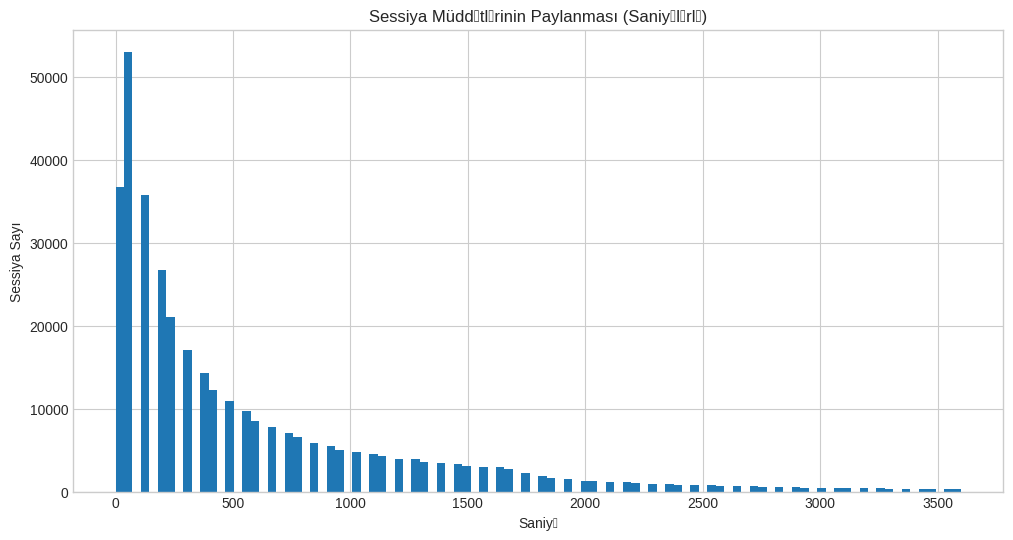

In [85]:
# Qrafik (Paylanma)
visits['duration_sec'].hist(bins=100, range=(0, 3600))
plt.title('Sessiya Müddətlərinin Paylanması (Saniyələrlə)')
plt.xlabel('Saniyə')
plt.ylabel('Sessiya Sayı')
plt.show()

Bu qrafik istifadəçilərin saytda keçirdiyi sessiya müddətlərinin (saniyələrlə) paylanmasını göstərir. Qrafikdən aydın görünür ki, paylanma sağa meyllidir (log-normal paylanmadır) və sessiyaların böyük əksəriyyəti çox qısa müddətlidir. Ən yüksək tezlik ilk 60-120 saniyə (1-2 dəqiqə) arasında müşahid olunur, yəni istifadəçilərin çoxu saytda cəmi 1-2 dəqiqə vaxt keçirir. Vaxt uzandıqca (500 saniyədən yuxarı) sessiya sayı kəskin şəkildə azalır. Paylanma simmetrik olmadığı üçün orta göstərici kimi ədədi orta (mean) əvəzinə median və ya mod dəyərindən istifadə etmək daha doğrudur, çünki uzun süren nadir sessiyalar orta qiyməti süni şəkildə şişirdə bilər. Yekun olaraq, istifadəçilər platformada qərarı tez verirlər və bilet/tədbir axtarışını qısa müddətdə tamamlayıb tətbiqdən çıxırlar.

##İstifadəçilərin saxlanma dərəcəsi (Retention Rate) necədir?

In [86]:
# İstifadəçinin ilk gəliş ayını tapırıq
first_visit = visits.groupby('uid')['start_ts'].min().dt.to_period('M').reset_index()
first_visit
first_visit.columns = ['uid', 'first_visit_month']
first_visit
visits_cohorts = pd.merge(visits, first_visit, on='uid')
visits_cohorts
visits_cohorts['visit_month'] = visits_cohorts['start_ts'].dt.to_period('M')
visits_cohorts.head()

,device,end_ts,source_id,start_ts,uid,session_year,session_month,session_week,session_date,duration_sec,first_visit_month,visit_month
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062,2017,2017-12,2017-12-18/2017-12-24,2017-12-20,1080.0,2017-12,2017-12
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740,2018,2018-02,2018-02-19/2018-02-25,2018-02-19,1680.0,2018-02,2018-02
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527,2017,2017-07,2017-06-26/2017-07-02,2017-07-01,0.0,2017-07,2017-07
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214,2018,2018-05,2018-05-14/2018-05-20,2018-05-20,1440.0,2018-03,2018-05
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168,2017,2017-12,2017-12-25/2017-12-31,2017-12-27,0.0,2017-12,2017-12


In [87]:
# Kohort yaşının (lifetime) hesablanması
visits_cohorts['cohort_lifetime'] = (visits_cohorts['visit_month'] - visits_cohorts['first_visit_month']).apply(lambda x: x.n)
visits_cohorts.head()

,device,end_ts,source_id,start_ts,uid,session_year,session_month,session_week,session_date,duration_sec,first_visit_month,visit_month,cohort_lifetime
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062,2017,2017-12,2017-12-18/2017-12-24,2017-12-20,1080.0,2017-12,2017-12,0
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740,2018,2018-02,2018-02-19/2018-02-25,2018-02-19,1680.0,2018-02,2018-02,0
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527,2017,2017-07,2017-06-26/2017-07-02,2017-07-01,0.0,2017-07,2017-07,0
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214,2018,2018-05,2018-05-14/2018-05-20,2018-05-20,1440.0,2018-03,2018-05,2
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168,2017,2017-12,2017-12-25/2017-12-31,2017-12-27,0.0,2017-12,2017-12,0


In [88]:
# Pivot cədvəl
cohort_data = visits_cohorts.groupby(['first_visit_month', 'cohort_lifetime']).agg({'uid': 'nunique'}).reset_index()
cohort_data.head()


,first_visit_month,cohort_lifetime,uid
0,2017-06,0,13259
1,2017-06,1,1043
2,2017-06,2,713
3,2017-06,3,814
4,2017-06,4,909


In [89]:
initial_users = cohort_data[cohort_data['cohort_lifetime'] == 0][['first_visit_month', 'uid']].rename(columns={'uid': 'cohort_users'})
initial_users.head()

,first_visit_month,cohort_users
0,2017-06,13259
12,2017-07,13140
23,2017-08,10181
33,2017-09,16704
42,2017-10,25977


In [90]:
cohort_data = pd.merge(cohort_data, initial_users, on='first_visit_month')
cohort_data
cohort_data['retention'] = (cohort_data['uid'] / cohort_data['cohort_users']*100).round(1)
cohort_data

retention_pivot = cohort_data.pivot(index='first_visit_month', columns='cohort_lifetime', values='retention')
retention_pivot


cohort_lifetime,0,1,2,3,4,5,6,7,8,9,10,11
first_visit_month,,,,,,,,,,,,
2017-06,100.0,7.9,5.4,6.1,6.9,7.1,6.1,5.8,5.2,5.1,4.1,4.5
2017-07,100.0,5.6,5.1,5.6,5.8,4.8,4.5,4.6,3.9,2.9,2.7,NaN
2017-08,100.0,7.7,6.3,6.3,5.0,4.4,3.6,3.9,2.8,2.6,NaN,NaN
2017-09,100.0,8.5,6.9,5.1,3.9,3.8,3.6,2.4,2.3,NaN,NaN,NaN
2017-10,100.0,7.9,5.2,3.9,3.4,3.2,2.1,2.0,NaN,NaN,NaN,NaN
2017-11,100.0,7.8,4.4,3.9,3.4,2.3,2.2,NaN,NaN,NaN,NaN,NaN
2017-12,100.0,5.6,3.8,3.1,2.0,1.9,NaN,NaN,NaN,NaN,NaN,NaN
2018-01,100.0,6.0,3.9,2.5,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-02,100.0,5.7,2.5,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 601 (\N{LATIN SMALL LETTER SCHWA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


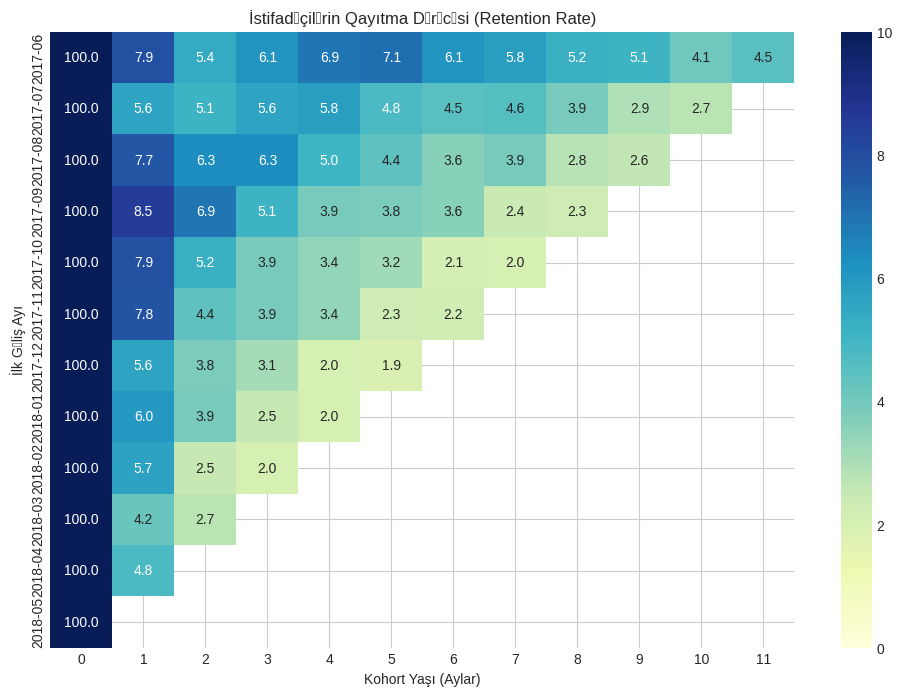

In [91]:
# Heatmap vizuallaşdırma

plt.figure(figsize=(12, 8))
sns.heatmap(retention_pivot, annot=True, fmt='.1f', cmap='YlGnBu', vmin=0, vmax=10)
plt.title('İstifadəçilərin Qayıtma Dərəcəsi (Retention Rate)')
plt.xlabel('Kohort Yaşı (Aylar)')
plt.ylabel('İlk Gəliş Ayı')
plt.show()

Bu istilik xəritəsi (Heatmap) istifadəçilərin platformaya qayıtma dərəcəsini (Retention Rate) kohortlar üzrə faizlə göstərir. İlk ayda (0-cı ay) bütün kohortlar üçün göstərici 100%-dir, çünki bu istifadəçilərin sayta ilk dəfə gəldiyi dövrdür. Növbəti ayda (1-ci ay) istifadəçi saxlanması kəskin düşür və bütün kohortlar üzrə təxminən 4.2% – 8.5% arasında dəyişir. Zaman keçdikcə (aylar artdıqca) qayıtma dərəcəsi tədricən azalmağa davam edir və 10-cu ayda 2.7% – 4.1% səviyyəsinə qədər enir. Ən yaxşı saxlanma göstəricisi 2017-ci ilin iyun və sentyabr-oktyabr kohortlarında müşahid olunur (1-ci ayda 7.9% – 8.5%). Ümumiyyətlə, Retention Rate aşağıdır, bu da platformanın istifadəçiləri uzunmüddətli özündə saxlamaqda çətinlik çəkdiyini və məhsul daxilində təkrar cəlbediciliyin (lallığın) artırılmasına ehtiyac olduğunu göstərir.

#2. Satışlar (Sales):
##İnsanlar nə vaxt almağa başlayırlar? (KPI analizində adətən qeydiyyat və konversiya — istifadəçini müştəriyə çevrilməsi — arasında keçən vaxtı bilməkdə maraqlıyıq. Məsələn, qeydiyyat və ilk alış eynigündə baş verərsə, istifadəçi Conversion 0d kateqoriyasına düşə bilər. İlk alış növbəti gün baş verərsə, bu Conversion 1d olacaq. Müxtəlif kohortların konversiyalarını müqayisə etməyə imkan verən hər hansı bir yanaşmadan istifadə edə bilərsiniz.)

In [92]:
# İlk ziyarət və ilk alış tarixlərini birleşdiririk
first_visit_date = visits.groupby('uid')['start_ts'].min().reset_index()
first_visit_date
first_order_date = orders.groupby('uid')['buy_ts'].min().reset_index()
first_order_date
conversion = pd.merge(first_visit_date, first_order_date, on='uid', how='inner')
conversion['days_to_convert'] = (conversion['buy_ts'] - conversion['start_ts']).dt.days
conversion['days_to_convert'].head()

,days_to_convert
0,106
1,0
2,0
3,0
4,0


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 601 (\N{LATIN SMALL LETTER SCHWA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


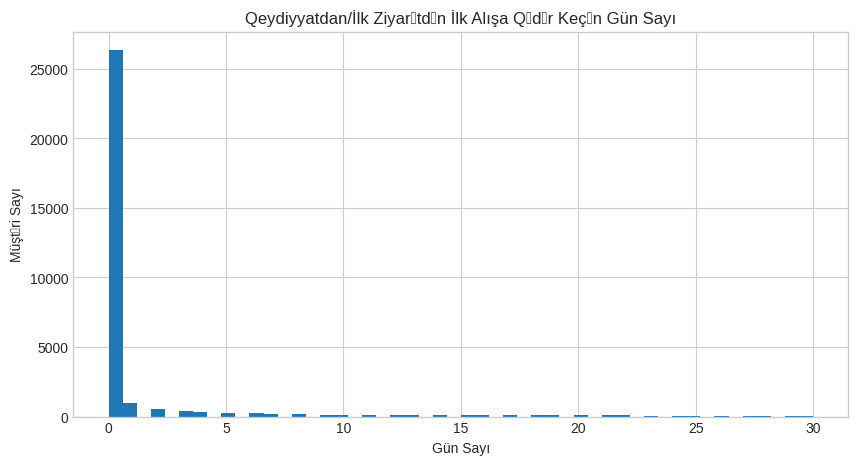

Müştərilərin 72.2%-i gəldiyi gün (0d) alış edir.


In [93]:
# Qrafik
plt.figure(figsize=(10, 5))
conversion['days_to_convert'].hist(bins=50, range=(0, 30))
plt.title('Qeydiyyatdan/İlk Ziyarətdən İlk Alışa Qədər Keçən Gün Sayı')
plt.xlabel('Gün Sayı')
plt.ylabel('Müştəri Sayı')
plt.show()

print(f"Müştərilərin { (conversion['days_to_convert'] == 0).mean()*100:.1f}%-i gəldiyi gün (0d) alış edir.")

Bu histoqram istifadəçilərin sayta ilk gəlişi (və ya qeydiyyatı) ilə ilk bilet/məhsul alışı arasında keçən günlərin paylanmasını gösterir. Qrafikdən çox aydın görünür ki, alıcıların əksəriyyəti — yəni 72.2%-i sayta gəldiyi elə ilk gündə (0-cı gün) alış-verişini reallaşdırır. İkinci gün (1-ci gün) konversiya olanların sayı kəskin şəkildə düşür (25,000-dən 2,000-in altına enir) və 2-ci gündən sonra bu rəqəm sıfıra yaxınlaşır. Bu göstərici onu sübut edir ki, platformada bilet alışı əsasən impulsivdir və ya istifadəçilər sayta konkret tədbir biletini almaq məqsədilə daxil olurlar. Yekun olaraq, marketinq strategiyasında istifadəçini elə ilk ziyarət anında tutmaq və tez alım etməyə təşviq edən addımlar (məsələn, dərhal görünən təkliflər və sadələşdirilmiş ödəniş prosesi) həlledici rol oynayır.

##Müəyyən bir zaman ərzində neçə sifariş edirlər?

In [94]:
#bir ayliq vaxt dilimi yaradaq
orders['buy_month'] = orders['buy_ts'].dt.to_period('M')
orders.head()

,buy_ts,revenue,uid,buy_month
0,2017-06-01 00:10:00,17.00,10329302124590727494,2017-06
1,2017-06-01 00:25:00,0.55,11627257723692907447,2017-06
2,2017-06-01 00:27:00,0.37,17903680561304213844,2017-06
3,2017-06-01 00:29:00,0.55,16109239769442553005,2017-06
4,2017-06-01 07:58:00,0.37,14200605875248379450,2017-06


In [95]:
# 'uid' üçün həm count, həm də nunique siyahı kimi verilir
orders_per_user = orders.groupby('buy_month').agg({'uid': ['count', 'nunique']}).reset_index()
orders_per_user.head()
# Sütun adlarını dəyişdirək
orders_per_user.columns = ['buy_month', 'total_orders', 'unique_buyers']
# Ortalamanı hesablayırıq
orders_per_user['orders_per_buyer'] = (orders_per_user['total_orders'] / orders_per_user['unique_buyers']).round(2)
orders_per_user

,buy_month,total_orders,unique_buyers,orders_per_buyer
0,2017-06,2354,2023,1.16
1,2017-07,2363,1984,1.19
2,2017-08,1807,1472,1.23
3,2017-09,3387,2750,1.23
4,2017-10,5679,4675,1.21
5,2017-11,5659,4547,1.24
6,2017-12,6218,4942,1.26
7,2018-01,4721,3898,1.21
8,2018-02,5281,4258,1.24
9,2018-03,5326,4181,1.27


/tmp/ipykernel_629/1125149177.py:46: UserWarning: Glyph 601 (\N{LATIN SMALL LETTER SCHWA}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 601 (\N{LATIN SMALL LETTER SCHWA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


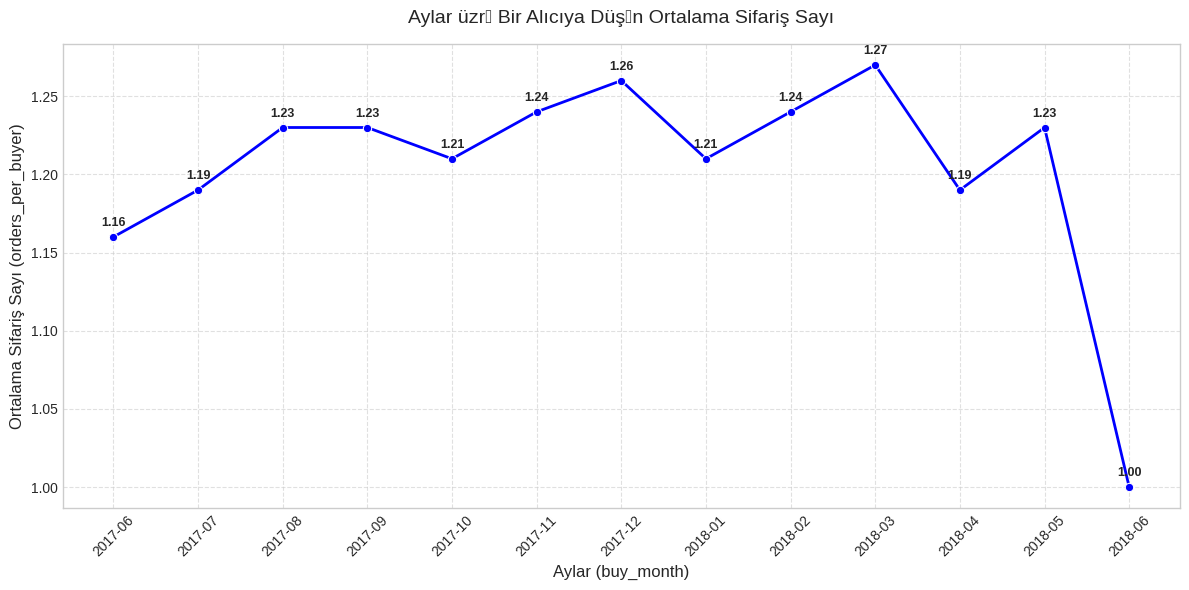

In [96]:
# Ölçünü təyin edirik
plt.figure(figsize=(12, 6))

# Xətti qrafik qururuq
ax = sns.lineplot(
    data=orders_per_user,
    x=orders_per_user['buy_month'].astype(str),
    y='orders_per_buyer',
    marker='o',
    color='b',
    linewidth=2,
)

# Qrafik üzərindəki başlıq və ox adları
plt.title(
    'Aylar üzrə Bir Alıcıya Düşən Ortalama Sifariş Sayı',
    fontsize=14,
    pad=15,
)
plt.xlabel('Aylar (buy_month)', fontsize=12)
plt.ylabel('Ortalama Sifariş Sayı (orders_per_buyer)', fontsize=12)

# X oxundakı yazıları 45 dərəcə bucaq altında meyilləndiririk
plt.xticks(rotation=45)

# Rahat görünüş üçün tor (grid) əlavə edirik
plt.grid(True, linestyle='--', alpha=0.6)

# Nöqtələrin üzərinə dəqiq rəqəmləri yazmaq üçün (isteğə bağlı)
for p in ax.patches:
    pass  # Lineplot üçün text aşağıdakı dövr ilə yazılır:

for x, y in zip(
    range(len(orders_per_user)), orders_per_user['orders_per_buyer']
):
    plt.text(
        x,
        y + 0.005,
        f'{y:.2f}',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
    )

plt.tight_layout()
plt.show()

Bu xətli qrafik aylar üzrə bir alıcıya düşən orta sifariş sayının dinamikasını göstərir. Ümumilikdə, dövrün böyük hissəsində bir müştəri ay ərzində orta hesabla 1.16 ilə 1.27 arasında sifariş verir. Ən yüksək göstərici 2018-ci ilin mart (1.27) və 2017-ci ilin dekabr (1.26) aylarında müşahid olunur ki, bu da bayram və ya mövsümi tədbir aktivliyi ilə bağlı ola bilər. 2018-ci ilin iyun ayında isə göstərici kəskin şəkildə 1.00 səviyyəsinə düşür, yəni alıcılar ay ərzində yalnız 1 dəfə sifariş ediblər (bu, ayın tam tamamlanmaması və ya natamam məlumatla əlaqədar ola bilər). Yekun olaraq, təkrar alış-veriş dərəcəsi kifayət qədər aşağıdır və istifadəçilər ay ərzində adətən 1-dən çox sifariş etməyə meylli deyillər.

In [121]:
visits['start_ts'].max()

Timestamp('2018-05-31 23:59:00')

Deməli Qrafikin sonundakı kəskin düşüş (1.00 səviyyəsinə enməsi) isə reallıqda müştəri aktivliyinin azalması ilə deyil, verilənlər bazasının son tarixinin 31 May 2018-ci il (23:59:00) olması ilə bağlıdır. Matplotlib vizuallaşdırma zamanı May ayının son dəqiqəsindəki bu məlumatı avtomatik növbəti dövrün (2018-06) başlanğıcı kimi etiketlədiyi üçün süni bir eniş görünür. Yekun olaraq, platformada təkrar alış-veriş dərəcəsi stabl olaraq 1.20 ətrafındadır və müştərilər ay ərzində adətən 1-dən çox sifariş etməyə meylli deyillər.

##Orta çek məbləği (ortalama alış ölçüsü) nə qədərdir?

In [97]:

orders_per_user['aov'] = orders.groupby('buy_month')['revenue'].sum().values / orders_per_user['total_orders']
orders_per_user

,buy_month,total_orders,unique_buyers,orders_per_buyer,aov
0,2017-06,2354,2023,1.16,4.060106
1,2017-07,2363,1984,1.19,5.306589
2,2017-08,1807,1472,1.23,4.847139
3,2017-09,3387,2750,1.23,5.416448
4,2017-10,5679,4675,1.21,4.928280
5,2017-11,5659,4547,1.24,4.783518
6,2017-12,6218,4942,1.26,5.852139
7,2018-01,4721,3898,1.21,4.112927
8,2018-02,5281,4258,1.24,4.840095
9,2018-03,5326,4181,1.27,5.413930


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 601 (\N{LATIN SMALL LETTER SCHWA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


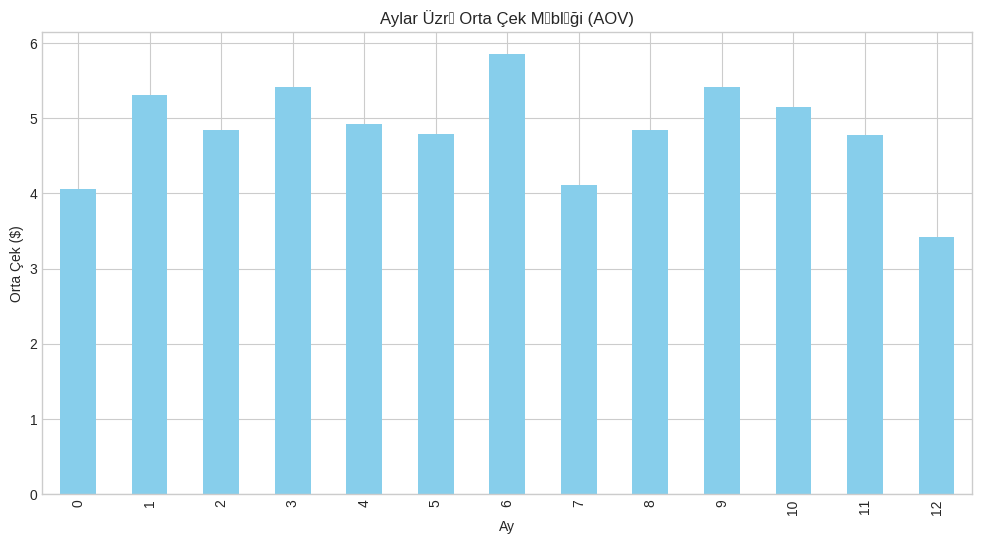

In [98]:
orders_per_user['aov'].plot(kind='bar', color='skyblue')
plt.title('Aylar Üzrə Orta Çek Məbləği (AOV)')
plt.xlabel('Ay')
plt.ylabel('Orta Çek ($)')
plt.show()

Bu sütunlu qrafik kohort yaşına (aylara) görə orta çek məbləğinin (AOV - Average Order Value) dəyişməsini göstərir. İstifadəçilərin alış-verişində orta çek dəyəri əsasən 4.0$ ilə 5.8$ aralığında stabil olaraq saxlanılır. Ən yüksek göstərici 6-cı ayda (təxminən 5.8$) müşahid olunur, 12-ci ayda isə kəskin azalaraq ən aşağı səviyyəyə (3.4$) düşür. Yekun olaraq, müştərilərin zaman keçdikcə etdiyi alış-verişlərin məbləği böyük sıçrayışlar etmir və ümumi xərcləmə vərdişləri sabit qalır.

##Hər bir müştəri nə qədər gəlir gətirir? (LTV - Lifetime Value)

In [99]:
orders
# Orders cədvəlinə müştərinin ilk gəliş ayını əlavə edirik
orders_cohorts = pd.merge(orders, visits_cohorts[['uid', 'first_visit_month']].drop_duplicates(), on='uid')
orders_cohorts.head()

,buy_ts,revenue,uid,buy_month,first_visit_month
0,2017-06-01 00:10:00,17.00,10329302124590727494,2017-06,2017-06
1,2017-06-01 00:25:00,0.55,11627257723692907447,2017-06,2017-06
2,2017-06-01 00:27:00,0.37,17903680561304213844,2017-06,2017-06
3,2017-06-01 00:29:00,0.55,16109239769442553005,2017-06,2017-06
4,2017-06-01 07:58:00,0.37,14200605875248379450,2017-06,2017-06


In [100]:
# Alışın baş verdiyi ay ilə ilk gəliş ayı arasındakı fərqi tapırıq
orders_cohorts['age'] = (orders_cohorts['buy_month'] - orders_cohorts['first_visit_month']).apply(lambda x: x.n)
orders_cohorts.head()

,buy_ts,revenue,uid,buy_month,first_visit_month,age
0,2017-06-01 00:10:00,17.00,10329302124590727494,2017-06,2017-06,0
1,2017-06-01 00:25:00,0.55,11627257723692907447,2017-06,2017-06,0
2,2017-06-01 00:27:00,0.37,17903680561304213844,2017-06,2017-06,0
3,2017-06-01 00:29:00,0.55,16109239769442553005,2017-06,2017-06,0
4,2017-06-01 07:58:00,0.37,14200605875248379450,2017-06,2017-06,0


In [101]:
#Hər kohortun hər ay üzrə ümumi gəlirini (Revenue) hesablayırıq:
cohorts_revenue = orders_cohorts.groupby(['first_visit_month', 'age'])['revenue'].sum().reset_index()
cohorts_revenue.head()

,first_visit_month,age,revenue
0,2017-06,0,9557.49
1,2017-06,1,2664.58
2,2017-06,2,1464.69
3,2017-06,3,3882.09
4,2017-06,4,3940.59


In [102]:
#Hər kohortda nə qədər İLK İSTİFADƏÇİ (ilkin kohort ölçüsü) olduğunu tapırıq:
cohort_sizes = visits_cohorts.groupby('first_visit_month')['uid'].nunique().reset_index()
cohort_sizes.columns = ['first_visit_month', 'cohort_users']
cohort_sizes.head()

,first_visit_month,cohort_users
0,2017-06,13259
1,2017-07,13140
2,2017-08,10181
3,2017-09,16704
4,2017-10,25977


In [103]:
#Gəlir cədvəli ilə ilkin kohort ölçüsünü birləşdirib bir müştəriyə düşən orta gəliri (LTV) tapırıq:
report = pd.merge(cohorts_revenue, cohort_sizes, on='first_visit_month')
report

# Hər ay üçün bir müştəriyə düşən orta gəlir
report['ltv'] = report['revenue'] / report['cohort_users']
report.head()

,first_visit_month,age,revenue,cohort_users,ltv
0,2017-06,0,9557.49,13259,0.720830
1,2017-06,1,2664.58,13259,0.200964
2,2017-06,2,1464.69,13259,0.110468
3,2017-06,3,3882.09,13259,0.292789
4,2017-06,4,3940.59,13259,0.297201


In [104]:
#Kumulyativ (Toplanaraq artan) LTV matrisini qururuq:
# Pivot cədvəl qurub kumulyativ cəmləyirik (.cumsum)
ltv_pivot = report.pivot_table(
    index='first_visit_month',
    columns='age',
    values='ltv'
).cumsum(axis=1).round(2)

ltv_pivot

age,0,1,2,3,4,5,6,7,8,9,10,11
first_visit_month,,,,,,,,,,,,
2017-06,0.72,0.92,1.03,1.33,1.62,1.84,2.10,2.27,2.44,2.71,2.87,3.02
2017-07,0.75,0.83,0.92,0.99,1.06,1.12,1.16,1.22,1.28,1.32,1.36,NaN
2017-08,0.61,0.71,0.81,0.90,0.98,1.03,1.08,1.20,1.29,1.32,NaN,NaN
2017-09,0.74,0.96,1.09,1.71,1.79,1.90,1.96,1.99,2.02,NaN,NaN,NaN
2017-10,0.71,0.85,0.90,0.95,0.99,1.02,1.05,1.07,NaN,NaN,NaN,NaN
2017-11,0.61,0.70,0.75,0.80,0.84,0.87,0.90,NaN,NaN,NaN,NaN,NaN
2017-12,0.67,0.74,0.90,1.10,1.16,1.23,NaN,NaN,NaN,NaN,NaN,NaN
2018-01,0.47,0.55,0.61,0.62,0.64,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-02,0.52,0.61,0.64,0.68,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 601 (\N{LATIN SMALL LETTER SCHWA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


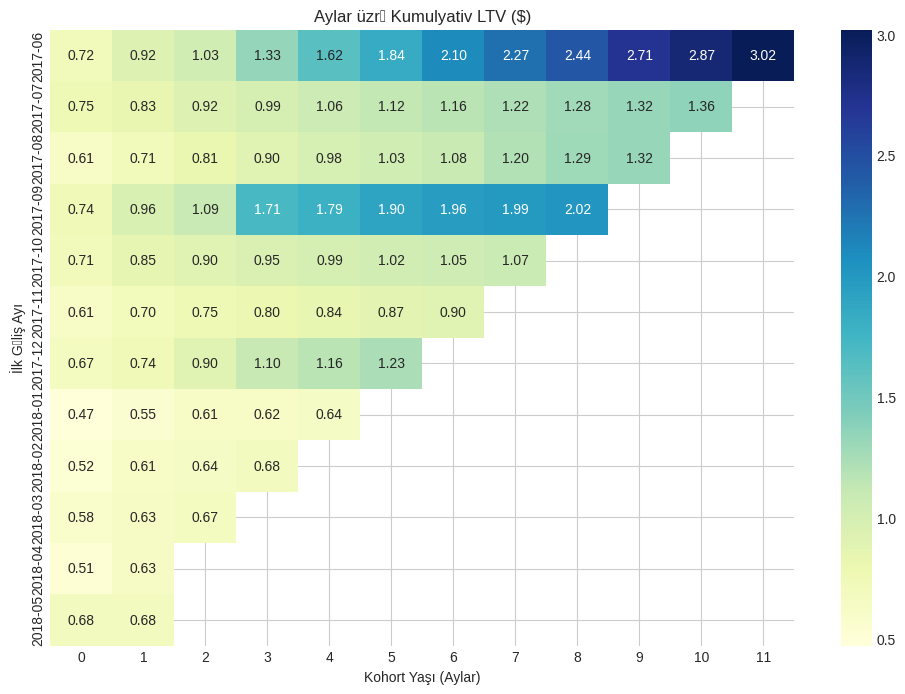

In [105]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
sns.heatmap(ltv_pivot, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Aylar üzrə Kumulyativ LTV ($)')
plt.xlabel('Kohort Yaşı (Aylar)')
plt.ylabel('İlk Gəliş Ayı')
plt.show()

Bu istilik xəritəsi (Heatmap) kohortlar üzrə müştərilərin zaman keçdikcə gətirdiyi kumulyativ gəliri (LTV - Ömürlük Dəyər) göstərir. Sağa doğru getdikcə dəyərlər təbii olaraq artır, burada ən böyük töhfəni 2017-ci ilin iyun kohortu verib — ilk ayda 0.72-la başlayıb 11-ci ayın sonunda 3.02-a qədər yüksəlib. Sentyabr 2017 kohortu da 2.02-a çataraq yaxşı nəticə göstərsə də, ümumilikdə 2018-ci ilin yeni kohortlarında ilk ay gəlirləri (0.47- 0.52) daha aşağı başlayır. Yekun olaraq, platformaya əvvəl gələn müştərilər zamanla daha çox gəlir qazandırdığı halda, yeni cəlb olunan müştərilərin monetize olunma dərəcəsi daha zəifdir.

#3. Marketinq (Marketing):
##Overall (Ümumi xərc): Bütün dövr ərzində reklama cəmi nə qədər pul xərclənib? (Tək bir ümumi cəm rəqəmi).

##Per source (Mənbələr üzrə): Hər bir reklam kanalına (source_id) ayrı-ayrılıqda neçə pul xərclənib və ən çox büdcə hansı kanala gedib?

##Over time (Zaman üzrə): Xərclər zamanla (aylar və ya günlər üzrə) necə dəyişib? Hansı aylarda reklam xərcləri artıb və ya azalıb?

In [106]:
# Ümumi xərc
total_cost = costs['costs'].sum()
total_cost
print(f"Ümumi Marketinq Xərci: ${total_cost:,.2f}")

Ümumi Marketinq Xərci: $329,131.62


In [107]:
# soource üzrə xərc
cost_per_source = costs.groupby('source_id')['costs'].sum().reset_index()
print("\nMənbələr üzrə xərclər:")
print(cost_per_source)


Mənbələr üzrə xərclər:
   source_id      costs
0          1   20833.27
1          2   42806.04
2          3  141321.63
3          4   61073.60
4          5   51757.10
5          9    5517.49
6         10    5822.49


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 601 (\N{LATIN SMALL LETTER SCHWA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 601 (\N{LATIN SMALL LETTER SCHWA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 601 (\N{LATIN SMALL LETTER SCHWA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


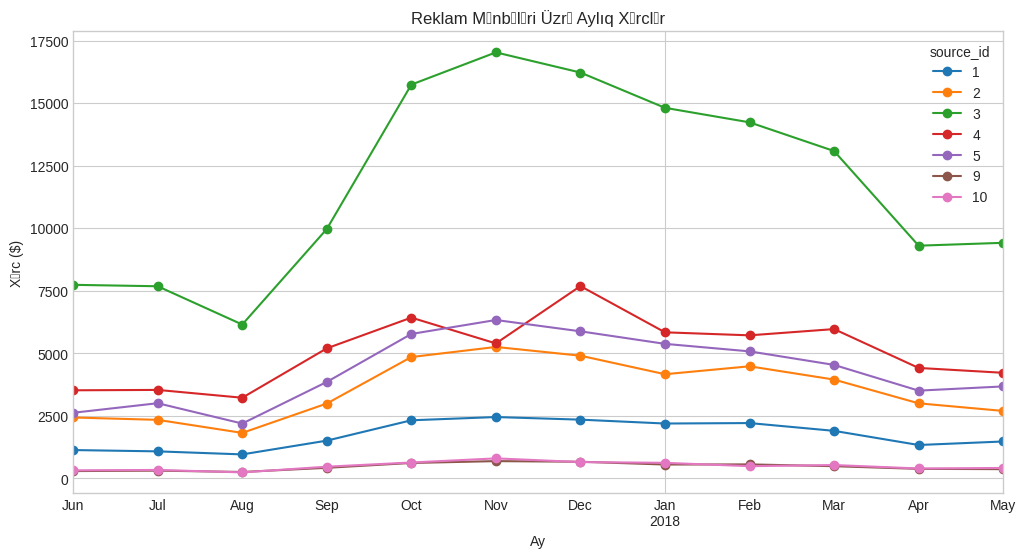

In [108]:
# Zaman üzrə xərc
costs['month'] = costs['dt'].dt.to_period('M')
costs.groupby(['month', 'source_id'])['costs'].sum().unstack().plot(kind='line', marker='o')
plt.title('Reklam Mənbələri Üzrə Aylıq Xərclər')
plt.xlabel('Ay')
plt.ylabel('Xərc ($)')
plt.show()

Bu xətli qrafik müxtəlif reklam mənbələri (source_id) üzrə aylıq xərclərin dinamikasını göstərir. Ən çox büdcə ayrılan kanal açıq-aydın source_id 3-dür; bu mənbəyə xərclər payız aylarında kəskin artaraq noyabrda maksimuma (17,500$-a yaxın) çatır. Source_id 4 və 5 də nisbətən yüksək xərc tələb edən kanallardır və pik nöqtələrini dekabr aylarında görürlər. Digər mənbələr (xüsusilə 1, 9 və 10) isə bütün dövr ərzində kifayət qədər aşağı və sabit büdcə ilə idarə olunur. Yekun olaraq, marketinq büdcəsinin böyük hissəsi 3-cü mənbəyə yönəldilib və ümumi xərclər payız-qış mövsümündə maksimum səviyyəyə çatır.

##Hər bir mənbədən müştəri cəlb edilməsi neçəyə başa gəlib? (CAC - Customer Acquisition Cost)

In [109]:
# Hər bir istifadəçinin ilk gəldiyi reklam mənbəyini tapırıq
first_source = visits.sort_values('start_ts').groupby('uid').first()['source_id'].reset_index()
first_source.head()

,uid,source_id
0,11863502262781,3
1,49537067089222,2
2,297729379853735,3
3,313578113262317,2
4,325320750514679,5


In [110]:
# Müştərilərin ilk alış məlumatı ilə birləşdiririk
buyers_source = pd.merge(orders, first_source, on='uid')
buyers_source.head()

,buy_ts,revenue,uid,buy_month,source_id
0,2017-06-01 00:10:00,17.00,10329302124590727494,2017-06,1
1,2017-06-01 00:25:00,0.55,11627257723692907447,2017-06,2
2,2017-06-01 00:27:00,0.37,17903680561304213844,2017-06,2
3,2017-06-01 00:29:00,0.55,16109239769442553005,2017-06,2
4,2017-06-01 07:58:00,0.37,14200605875248379450,2017-06,3


In [111]:
# Mənbələr üzrə müştəri sayı
buyers_per_source = buyers_source.groupby('source_id').agg({'uid': 'nunique'}).reset_index()
buyers_per_source.columns = ['source_id', 'n_buyers']
buyers_per_source.head()

,source_id,n_buyers
0,1,2899
1,2,3506
2,3,10473
3,4,10296
4,5,6931


In [112]:
# CAC hesablanması
cac_df = pd.merge(cost_per_source, buyers_per_source, on='source_id')
cac_df['cac'] = cac_df['costs'] / cac_df['n_buyers']
cac_df

,source_id,costs,n_buyers,cac
0,1,20833.27,2899,7.186364
1,2,42806.04,3506,12.209367
2,3,141321.63,10473,13.493901
3,4,61073.60,10296,5.931779
4,5,51757.10,6931,7.467479
5,9,5517.49,1088,5.071222
6,10,5822.49,1329,4.381106


/tmp/ipykernel_629/3949157735.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cac_df, x='source_id', y='cac', palette='magma')
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 601 (\N{LATIN SMALL LETTER SCHWA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


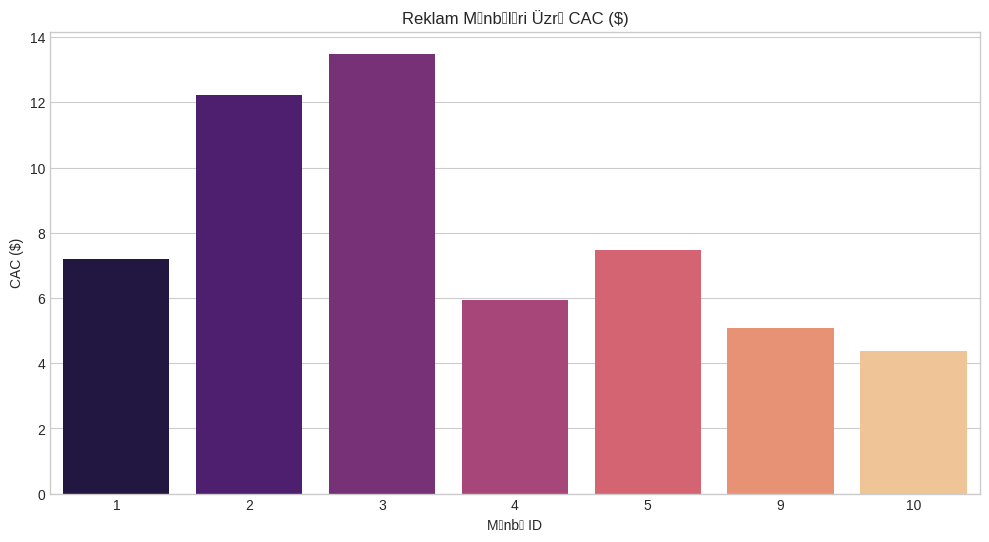

In [113]:
# Qrafik
sns.barplot(data=cac_df, x='source_id', y='cac', palette='magma')
plt.title('Reklam Mənbələri Üzrə CAC ($)')
plt.xlabel('Mənbə ID')
plt.ylabel('CAC ($)')
plt.show()

Bu sütunlu qrafik müxtəlif reklam mənbələri üzrə bir alıcını cəlb etmək üçün çəkilən xərci (CAC - Müştəri Cəlb Etmə Xərci) göstərir. Ən yüksək CAC göstəricisi source_id 3 (təxminən 13.5) və source_id 2 (təxminən 12.2) mənbələrindədir, yəni bu kanallardan müştəri gətirmək kifayət qədər baha başa gəlir. Ən sərfəli və ucuz müştəri cəlb edən kanallar isə source_id 10 (təxminən 4.3$) və source_id 9-dur. Yekun olaraq, büdcəni optimallaşdırmaq üçün baha olan 2 və 3-cü mənbələrin gəlirliliyi (LTV-si) yoxlanılmalı və gərəkərsə büdcə daha ucuz kanallara yönəldilməlidir.

##İnvestisiyalar nə dərəcədə səmərəli olub? (ROI / ROMI)

In [119]:
# Mənbələrə görə toplanan gəlir
buyer_revenue = orders.groupby('uid')['revenue'].sum().reset_index()
buyer_revenue
source_revenue = pd.merge(buyers_source[['uid', 'source_id']], buyer_revenue, on='uid')
source_revenue
summary_romi = source_revenue.groupby('source_id')['revenue'].sum().reset_index()
summary_romi
summary_romi = pd.merge(summary_romi, cost_per_source, on='source_id')
summary_romi
summary_romi['romi'] = (summary_romi['revenue'] / summary_romi['costs']) * 100
summary_romi


,source_id,revenue,costs,romi
0,1,1261771.98,20833.27,6056.523916
1,2,901571.96,42806.04,2106.179315
2,3,168587.35,141321.63,119.293381
3,4,265315.03,61073.60,434.418521
4,5,1792971.99,51757.10,3464.204892
5,9,21260.81,5517.49,385.334817
6,10,6501.95,5822.49,111.669578


/tmp/ipykernel_629/1028407650.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary_romi, x='source_id', y='romi', palette='viridis')
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 601 (\N{LATIN SMALL LETTER SCHWA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


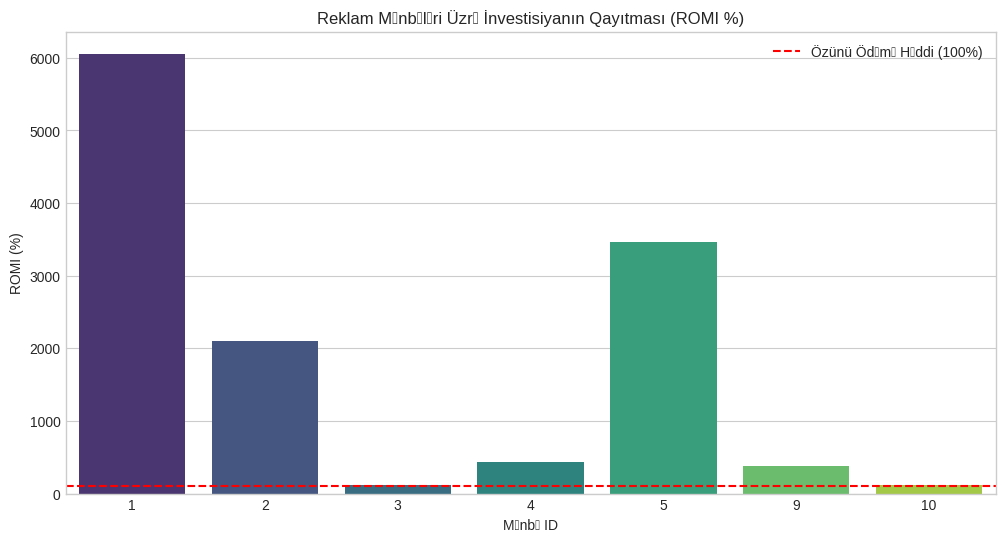

In [120]:
# Qrafik
sns.barplot(data=summary_romi, x='source_id', y='romi', palette='viridis')
plt.axhline(100, color='red', linestyle='--', label='Özünü Ödəmə Həddi (100%)')
plt.title('Reklam Mənbələri Üzrə İnvestisiyanın Qayıtması (ROMI %)')
plt.xlabel('Mənbə ID')
plt.ylabel('ROMI (%)')
plt.legend()
plt.show()

Bu sütunlu qrafik müxtəlif reklam mənbələri üzrə investisiyanın gəlirliliyini (ROMI) göstərir. Source_id 1 6000%-dən yuxarı göstərici ilə ən çox qazanc gətirən kanaldır, onu 5 və 2 nömrəli mənbələr izləyir. Qırmızı qırıq xətt özünüödəmə həddini (100%) təmsil edir; source_id 3 və 10 bu xəttin altında qalaraq çəkilən xərci ödəyə bilmir. Yekun olaraq, gəlirsiz olan 3-cü kanala ayrılan böyük büdcəni kəsib, effektivliyi ən yüksək olan 1 və 5-ci mənbələrə yatırmaq lazımdır.

#Yekun Nəticələr:

Məhsul və İstifadəçi Davranışı: İstifadəçilər platformada çox az vaxt keçirir (median sessiya müddəti 1-2 dəqiqədir) və alıcıların 72.2%-i ilk gəliş günündə alış edir. Qayıtma dərəcəsi (Retention Rate) aşağıdır (1-ci ayda təxminən 4-8%) və alıcılar ayda orta hesabla cəmi 1.2 dəqiqə bilet alırlar.

Gəlirlilik və LTV: Müştərilərin orta çek məbləği (AOV) 4-5$ arasında sabit qalır. Ən keyfiyyətli və gəlirli müştərilər 2017-ci ilin iyun və sentyabr kohortları ilə gələnlərdir.

Marketinq Effektivliyi: Reklam büdcəsinin böyük hissəsi Source 3-ə ayrılsa da, bu kanalın müştəri cəlbetmə xərci (CAC) yüksəkdir (13.5$) və gəlirlilik həddini (ROMI < 100%) ödəmir. Ən yüksək ROMI göstəricisi isə Source 1 (6000%+) və Source 5 (3500%) kanallarındadır.

#Biznes Tövsiyələri:

Reklam Büdcəsinin Yenidən Bölüşdürülməsi: Zərərə işləyən və özünü ödəməyən Source 3 və Source 10 kanallarına xərclənən büdcə kəsilməlidir. Bu resurslar gəlirliliyi ən yüksək olan Source 1 və Source 5 kanallarına yönəldilməlidir.

Qayıtma Dərəcəsinin (Retention) Artırılması: İstifadəçilərin təkrar alış-veriş etməsi üçün sodiqlik proqramları (loyalty program), şəxsi endirim kuponları və retargetinq xəbərdarlıqları tətbiq edilməlidir.

İlk Ziyarət Konversiyasının Gücləndirilməsi: Alıcılar impulsiv qərar verdiyi üçün sayta daxil olduqları ilk anlarda onlara ən populyar tədbirlər və sadələşdirilmiş 1-kliklə ödəniş imkanı təklif edilməlidir.